# AqSolDB Initial Modeling with Morgan Fingerprints

Explore the training data, fit baseline regressors and a Random Forest, and examine prediction errors and feature importance. The target is measured aqueous solubility in logS units. The predictors are the original 17 molecular descriptors and 1,024 Morgan fingerprint bits produced in Notebook 1.

Use Python 3 with NumPy, pandas, Matplotlib, and scikit-learn. Place **aqsoldb_cleaned_with_morgan.csv** in the working directory or run Notebook 1 to generate it in **data/processed_morgan**.

## 1. Set Up the Environment

Import the libraries and set a fixed seed for reproducible splits, model fitting, and permutation importance.

In [1]:
import os  # 查看可用的处理器数量 / Check the number of available processors
from pathlib import Path  # 使用相对路径找到 CSV / Locate the CSV using relative paths
import matplotlib.pyplot as plt  # 绘制探索和误差分析图 / Draw exploratory and error-analysis plots
import numpy as np  # 处理特征矩阵和预测值 / Work with feature matrices and predictions
import pandas as pd  # 读入数据和整理结果表 / Load the data and organize result tables
from IPython.display import Markdown, display  # 显示结果表和文字总结 / Display tables and written summaries
from sklearn.base import clone  # 为每个折创建一个未训练的模型 / Create an unfitted estimator for each fold
from sklearn.dummy import DummyRegressor  # 建立预测训练集均值的基线 / Build the training-mean baseline
from sklearn.ensemble import RandomForestRegressor  # 导入随机森林回归 / Import Random Forest regression
from sklearn.linear_model import Ridge  # 导入带正则化的线性基线 / Import the regularized linear baseline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # 导入三种回归评估指标 / Import three regression metrics
from sklearn.model_selection import GroupKFold, GroupShuffleSplit  # 用分组方式划分和验证 / Split and validate while keeping groups together
from sklearn.pipeline import make_pipeline  # 将缩放与 Ridge 模型绑定 / Combine scaling with the Ridge estimator
from sklearn.preprocessing import StandardScaler  # 基于每折训练数据标准化特征 / Scale features using each fold's training data

SEED = 42  # 固定本次实验的随机种子 / Fix the experiment seed
TEST_FRACTION = 0.20  # 预留约五分之一的连接组 / Reserve about one fifth of connectivity groups
N_FOLDS = 5  # 在训练集内进行五折验证 / Use five folds within the training partition
N_JOBS = min(6, os.cpu_count() or 1)  # 限制森林训练使用的线程数量 / Limit workers used by the forest

## 2. Load the Cleaned Data

Check that each molecule has a unique ID, a valid connectivity key, and complete numerical inputs. The InChIKey connectivity block identifies groups for splitting. The model uses the numerical descriptors and fingerprints.

In [2]:
data_path = Path("aqsoldb_cleaned_with_morgan.csv")  # 使用可以在其他电脑复跑的相对路径 / Use a portable relative path
if not data_path.is_file():  # 如果运行目录中没有 CSV，就查找 Notebook 1 的输出 / Check the Notebook 1 export if the CSV is absent here
    data_path = Path("data") / "processed_morgan" / data_path.name  # 使用清洗 notebook 的导出位置 / Use the cleaning notebook output path
if not data_path.is_file():  # 核对两种可能的路径是否都没有文件 / Check whether both locations are missing the file
    raise FileNotFoundError("Put aqsoldb_cleaned_with_morgan.csv beside this notebook or run Notebook 1.")  # 提示正确的文件名 / Give the exact filename
df = pd.read_csv(data_path)  # 读取清洗完成的数据表 / Load the cleaned dataset
descriptor_cols = [  # 明确列出原来的 17 个描述符 / List the 17 original descriptors explicitly
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount",  # 分子大小、亲油性、折射度和重原子数 / Size, lipophilicity, refractivity, and heavy atoms
    "NumHAcceptors", "NumHDonors", "NumHeteroatoms", "NumRotatableBonds",  # 氢键、杂原子和可旋转键 / Hydrogen bonds, heteroatoms, and rotatable bonds
    "NumValenceElectrons", "NumAromaticRings", "NumSaturatedRings", "NumAliphaticRings",  # 价电子和不同类型的环 / Valence electrons and ring types
    "RingCount", "TPSA", "LabuteASA", "BalabanJ", "BertzCT",  # 总环数、表面积和结构复杂度 / Ring count, surface areas, and structural complexity
]  # 结束描述符列表 / End the descriptor list
morgan_cols = [f"Morgan_{i:04d}" for i in range(1024)]  # 按固定顺序列出 1,024 个指纹列 / List the 1,024 fingerprint columns in order
required = ["ID", "InChIKey", "Solubility", *descriptor_cols, *morgan_cols]  # 列出本流程需要的字段 / List the required fields
missing = sorted(set(required) - set(df.columns))  # 发现缺失的必要列 / Find missing required columns
if missing:  # 若输入结构不对则给出明确提示 / Stop with a clear message if the schema is wrong
    raise ValueError(f"Required columns are missing: {', '.join(missing[:10])}")  # 列出前十个缺失名称 / List up to ten missing names
if df["ID"].isna().any() or not df["ID"].is_unique:  # 核对每条分子记录都有唯一 ID / Verify that each record has a unique ID
    raise ValueError("Expected unique nonmissing IDs.")  # 提示输入条件 / Explain the input condition
y = df["Solubility"].to_numpy(dtype=float)  # 把实测 logS 转成目标数组 / Convert measured logS to the target array
x_desc = df[descriptor_cols].to_numpy(dtype=np.float32)  # 提取描述符的数值矩阵 / Extract the descriptor matrix
x_bits = df[morgan_cols].to_numpy()  # 提取 Morgan 位矩阵 / Extract the Morgan bit matrix
if not (np.isfinite(y).all() and np.isfinite(x_desc).all() and np.isin(x_bits, [0, 1]).all()):  # 验证目标、描述符和二进制指纹 / Check the target, descriptors, and binary bits
    raise ValueError("Expected finite solubility and descriptors, and Morgan bits of 0 or 1.")  # 提示重新检查上游清洗 / Explain which inputs need checking
connectivity = df["InChIKey"].str.slice(0, 14)  # 用 InChIKey 前 14 位定义连接组 / Define connectivity groups from the first 14 InChIKey characters
if not connectivity.str.fullmatch("[A-Z]{14}", na=False).all():  # 检查连接组标签格式 / Check the connectivity-group format
    raise ValueError("Expected a valid connectivity block in every InChIKey.")  # 指明分组输入问题 / Explain the grouping input issue

X = np.column_stack([x_desc, x_bits]).astype(np.float32, copy=False)  # 将描述符和指纹组合成模型输入 / Combine descriptors and fingerprints into the model matrix
print(f"Loaded {len(df):,} molecules with {X.shape[1]:,} predictors.")  # 汇报数据规模 / Report the dataset size

Loaded 9,980 molecules with 1,041 predictors.


## 3. Set Aside Holdout Groups

Group molecules by the first 14 characters of their InChIKey. Keep records from each group together. Set aside about 20% of these groups, then define five validation folds within the remaining rows. The exploratory plots and model estimates below come from that training partition.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SEED)  # 按分子连接组生成固定划分 / Make a fixed split by molecular connectivity
train_rows, holdout_rows = next(splitter.split(X, groups=connectivity))  # 取得训练和留出集的原始行号 / Get original row indices for training and holdout
train_groups = connectivity.iloc[train_rows].to_numpy()  # 取得训练分子的连接组 / Get connectivity labels for the training molecules
assert set(train_groups).isdisjoint(connectivity.iloc[holdout_rows]), "Connectivity group overlap."  # 核对训练集和留出集组不重叠 / Check that groups do not cross the holdout
X_train, y_train = X[train_rows], y[train_rows]  # 取出本次用于训练与内部验证的数据 / Select data for fitting and internal validation
cv = GroupKFold(n_splits=N_FOLDS)  # 创建把同一连接组留在一起的五折划分器 / Define a five-fold splitter that keeps groups together
folds = list(cv.split(X_train, y_train, groups=train_groups))  # 保存三个模型共用的折 / Save the folds shared by all three models
for fit_idx, validation_idx in folds:  # 核对每个内部验证折 / Audit each internal validation fold
    assert set(train_groups[fit_idx]).isdisjoint(train_groups[validation_idx]), "Validation group overlap."  # 确认训练折和验证折不共用连接组 / Confirm that each fold separates its groups
print(f"Training partition: {len(train_rows):,} rows | Reserved holdout: {len(holdout_rows):,} rows")  # 汇报两部分数据的行数 / Report the two partition sizes

Training partition: 7,968 rows | Reserved holdout: 2,012 rows


## 4. Explore the Training Data

Plot the distribution of measured logS and its relationship with calculated lipophilicity (MolLogP) and molecular weight (MolWt). Spearman correlation summarizes whether logS tends to rise or fall as each descriptor increases.

,Descriptor,Spearman correlation with logS
0,MolLogP,-0.752
1,MolWt,-0.547


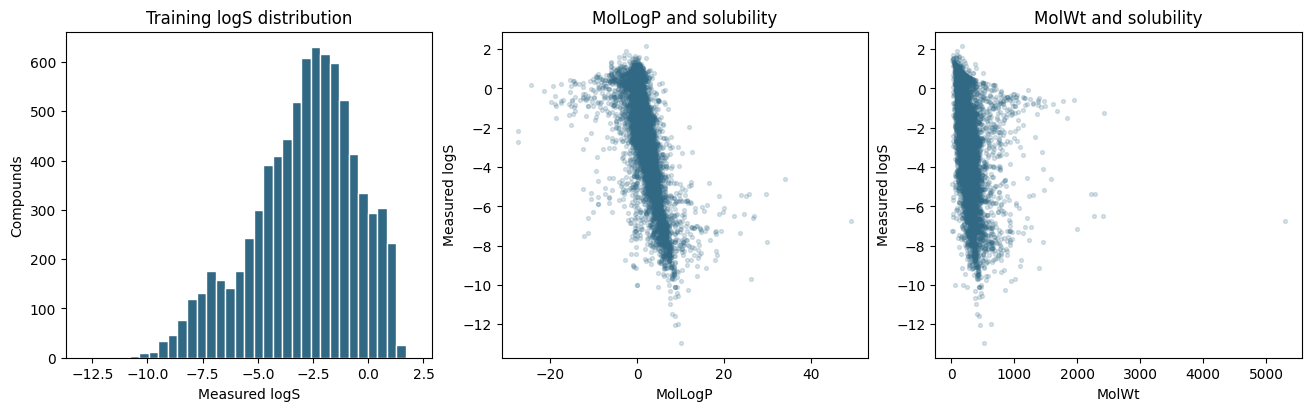

In [4]:
eda_data = df.iloc[train_rows][["MolLogP", "MolWt"]].copy()  # 仅提取训练行的两个描述符 / Select two descriptors from the training rows
eda_data["Measured logS"] = y[train_rows]  # 加入相同行的实测溶解度 / Add measured solubility for the same rows
eda_correlations = (  # 整理两个相关系数 / Prepare the two correlations
    eda_data.corr(method="spearman")["Measured logS"]  # 计算与实测溶解度的秩相关 / Calculate rank correlations with measured logS
    .loc[["MolLogP", "MolWt"]]  # 保留要解释的两个描述符 / Keep the two descriptors of interest
    .rename("Spearman correlation with logS")  # 为相关系数列命名 / Name the correlation column
    .rename_axis("Descriptor")  # 为行索引命名 / Name the row index
    .reset_index()  # 生成可直接保存的表格 / Convert to an export-ready table
)  # 得到训练集相关性表 / Finish the training correlation table
display(eda_correlations.round(3))  # 展示三位小数的相关性 / Display the correlations to three decimal places
eda_fig, eda_axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)  # 创建三个探索性图 / Create three exploratory plots
eda_axes[0].hist(eda_data["Measured logS"], bins=35, color="#316985", edgecolor="white")  # 绘制训练集目标分布 / Plot the training target distribution
eda_axes[0].set(xlabel="Measured logS", ylabel="Compounds", title="Training logS distribution")  # 添加坐标轴和标题 / Label the axes and title
for eda_axis, descriptor in zip(eda_axes[1:], ["MolLogP", "MolWt"]):  # 依次绘制两个描述符 / Plot the two descriptors in order
    eda_axis.scatter(eda_data[descriptor], eda_data["Measured logS"], s=8, alpha=0.18, color="#316985", rasterized=True)  # 绘制描述符与实测值的散点 / Plot the descriptor against measured logS
    eda_axis.set(xlabel=descriptor, ylabel="Measured logS", title=f"{descriptor} and solubility")  # 标注坐标轴和标题 / Label each panel
plt.show()  # 展示训练数据图 / Display the training data figure

## 5. Fit the Baselines and Evaluate Random Forest

Compare a training-mean baseline, Ridge regression, and a fixed-parameter Random Forest. Ridge and Random Forest use all 1,041 inputs. Fit Ridge's scaling within each fold. Each row receives a prediction from a model fitted on the other four folds. Pool these predictions and report RMSE, MAE, and R² across the training partition.

In [5]:
models = {  # 指定两个基线和固定参数的随机森林 / Define two baselines and a fixed Random Forest
    "Training mean": DummyRegressor(strategy="mean"),  # 用该折训练溶解度的均值预测 / Predict the fold's mean training solubility
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),  # 在每个训练折内标准化和拟合岭回归 / Scale and fit Ridge within each fold
    "Random Forest": RandomForestRegressor(n_estimators=96, max_features=0.45, min_samples_leaf=2, random_state=SEED, n_jobs=N_JOBS),  # 用固定参数拟合森林 / Fit the forest with fixed settings
}  # 完成三个模型的定义 / Finish defining the three estimators
predictions = {}  # 保存各模型的折外预测 / Store out-of-fold predictions per model
metric_rows = []  # 准备汇总三个评估指标 / Collect three metrics per model
for model_name, estimator in models.items():  # 在相同的验证划分上运行三个模型 / Use the same validation splits for all three models
    oof = np.full(len(y_train), np.nan)  # 预留每条训练记录的折外预测位置 / Allocate a prediction slot for each training row
    for fold_number, (fit_idx, validation_idx) in enumerate(folds, start=1):  # 依次在每折拟合和预测 / Fit and predict one fold at a time
        fitted = clone(estimator).fit(X_train[fit_idx], y_train[fit_idx])  # 只用当前训练折拟合模型 / Fit only on the current fold's training rows
        oof[validation_idx] = fitted.predict(X_train[validation_idx])  # 给本折验证行生成预测 / Predict the current validation rows
        if model_name == "Random Forest" and fold_number == 1:  # 复用预先指定的第一折森林做重要性分析 / Keep the prespecified first-fold forest for importance
            initial_importance_model = fitted  # 记录第一折拟合好的森林 / Save the fitted first-fold forest
    assert np.isfinite(oof).all(), f"Missing predictions for {model_name}."  # 核实每行都有可用预测 / Verify that every row has a finite prediction
    predictions[model_name] = oof  # 保存此模型的全部折外预测 / Save all out-of-fold predictions for this model
    metric_rows.append({  # 汇总该模型的预测成绩 / Summarize the model's validation results
        "Model": model_name,  # 记录模型的名称 / Record the estimator name
        "RMSE": np.sqrt(mean_squared_error(y_train, oof)),  # 计算更重视大误差的均方根误差 / Compute RMSE, which weights larger errors more strongly
        "MAE": mean_absolute_error(y_train, oof),  # 计算平均预测偏差的绝对值 / Compute the mean absolute prediction error
        "R²": r2_score(y_train, oof),  # 计算决定系数 / Compute the coefficient of determination
    })  # 完成该模型的成绩记录 / Finish the score row for this model
metrics = pd.DataFrame(metric_rows).set_index("Model")  # 整理三种模型的成绩表 / Assemble scores for all three models
display(metrics.round(3))  # 展示汇总后的折外成绩 / Display pooled out-of-fold scores

,RMSE,MAE,R²
Model,,,
Training mean,2.378,1.899,-0.000
Ridge,1.454,1.075,0.626
Random Forest,1.070,0.729,0.797


## 6. Examine Random Forest Prediction Errors

Compare measured and predicted logS using the out-of-fold predictions. A positive residual indicates overprediction. Group the errors by measured logS quartile to identify the ranges with the highest average absolute error.

,Measured logS band,Compounds,MAE,Bias
0,"(-12.951, -4.367]",1992,0.940,0.648
1,"(-4.367, -2.620]",1995,0.620,0.124
2,"(-2.620, -1.220]",1992,0.553,-0.172
3,"(-1.220, 2.138]",1989,0.803,-0.667


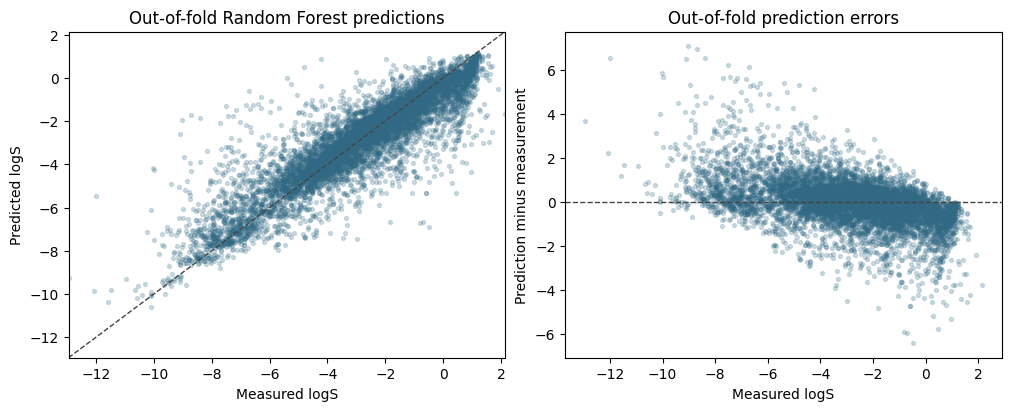

In [6]:
initial_forest_pred = predictions["Random Forest"]  # 读取随机森林的折外预测 / Retrieve the forest's out-of-fold predictions
initial_oof = df.iloc[train_rows][["ID"]].reset_index(drop=True)  # 用分子 ID 对齐预测记录 / Align predictions to molecule IDs
initial_oof["Measured logS"] = y_train  # 记录实测值 / Record measured values
initial_oof["Random Forest prediction"] = initial_forest_pred  # 记录森林预测 / Record forest predictions
initial_oof["Residual"] = initial_forest_pred - y_train  # 用预测减实测计算残差 / Compute residuals as predicted minus measured
initial_oof["Absolute error"] = initial_oof["Residual"].abs()  # 计算残差的绝对值 / Calculate absolute residuals
initial_oof["Measured logS band"] = pd.qcut(y_train, q=4, duplicates="drop")  # 按实测 logS 四分位数划分展示区间 / Summarize results by measured-logS quartile
initial_errors_by_band = (  # 按区间汇总森林误差 / Summarize forest errors by band
    initial_oof.groupby("Measured logS band", observed=True)  # 对属于同一区间的行分组 / Group rows in the same band
    .agg(Compounds=("Absolute error", "size"), MAE=("Absolute error", "mean"), Bias=("Residual", "mean"))  # 汇总样本数、误差和偏差 / Report count, absolute error, and bias
    .reset_index()  # 将区间作为普通列保存 / Store the band as a regular column
)  # 完成分区误差表 / Finish the error-by-band table
band_labels = initial_errors_by_band["Measured logS band"].map(lambda band: f"({band.left:.3f}, {band.right:.3f}]")  # 将区间边界显示为三位小数 / Show interval bounds to three decimal places
display(initial_errors_by_band.assign(**{"Measured logS band": band_labels}).round(3))  # 展示各区间的误差和偏差 / Display error and bias by solubility band

initial_error_fig, initial_error_axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)  # 创建预测图和误差图 / Create prediction and residual plots
initial_limits = [min(y_train.min(), initial_forest_pred.min()), max(y_train.max(), initial_forest_pred.max())]  # 统一实测值和预测值的坐标范围 / Use the same limits for measured and predicted values
initial_error_axes[0].scatter(y_train, initial_forest_pred, s=8, alpha=0.22, color="#316985", rasterized=True)  # 对照实测和预测 / Compare measured and predicted values
initial_error_axes[0].plot(initial_limits, initial_limits, color="#444444", linestyle="--", linewidth=1)  # 添加完美预测参考线 / Add the ideal-prediction line
initial_error_axes[0].set(xlabel="Measured logS", ylabel="Predicted logS", title="Out-of-fold Random Forest predictions", xlim=initial_limits, ylim=initial_limits)  # 标注预测图 / Label the prediction plot
initial_error_axes[1].scatter(y_train, initial_oof["Residual"], s=8, alpha=0.22, color="#316985", rasterized=True)  # 展示误差随实测值的变化 / Show how residuals vary with measured values
initial_error_axes[1].axhline(0, color="#444444", linestyle="--", linewidth=1)  # 标出无偏差参考线 / Add a zero-residual reference line
initial_error_axes[1].set(xlabel="Measured logS", ylabel="Prediction minus measurement", title="Out-of-fold prediction errors")  # 标注误差图 / Label the residual plot
plt.show()  # 展示两个诊断图 / Display both diagnostic plots

## 7. Estimate Permutation Importance

Use the Random Forest from the first fold and that fold's validation rows. Shuffle each descriptor individually and shuffle all Morgan bits together as a block. Report the resulting increase in validation RMSE. The scores describe the fitted model on one fold and can be affected by correlations among features.

,Feature group,RMSE increase,Repeat SD
0,MolLogP,1.316,0.017
1,MolWt,0.149,0.011
2,Morgan fingerprint block,0.141,0.004
3,MolMR,0.110,0.009
4,BertzCT,0.103,0.002
5,BalabanJ,0.059,0.010
6,LabuteASA,0.042,0.003
7,TPSA,0.038,0.002
8,NumHAcceptors,0.024,0.001
9,NumHDonors,0.013,0.003


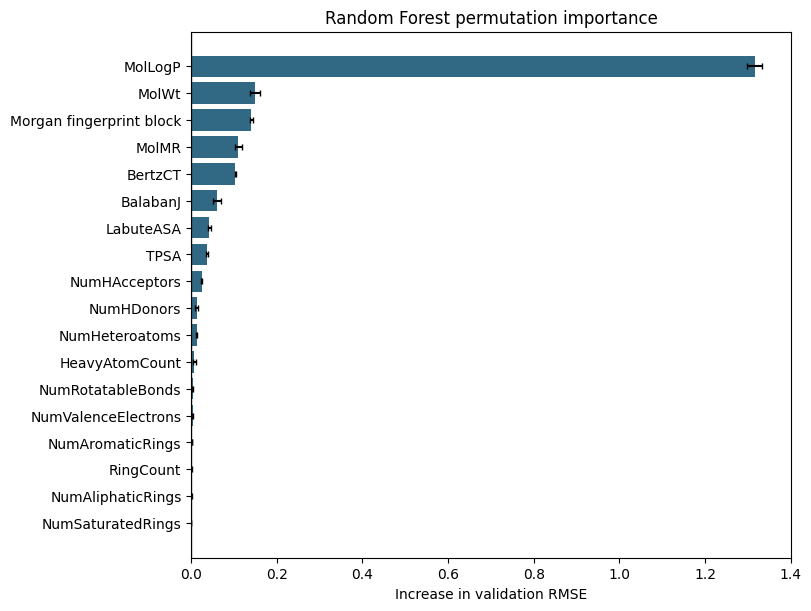

In [7]:
initial_importance_rows = folds[0][1]  # 使用第一折未参与拟合的验证行 / Use the validation rows from the first fold
initial_validation_X = X_train[initial_importance_rows]  # 取第一折的验证特征 / Get the first fold's validation features
initial_validation_y = y_train[initial_importance_rows]  # 取第一折的验证目标 / Get the first fold's validation target
initial_validation_pred = initial_forest_pred[initial_importance_rows]  # 复用验证行本来的预测 / Reuse the original validation predictions
initial_reference_rmse = np.sqrt(mean_squared_error(initial_validation_y, initial_validation_pred))  # 计算未打乱时的参考误差 / Calculate the unpermuted reference error
initial_feature_groups = [(name, slice(index, index + 1)) for index, name in enumerate(descriptor_cols)]  # 每个描述符单独作为一个变量组 / Treat each descriptor as its own feature group
initial_feature_groups.append(("Morgan fingerprint block", slice(len(descriptor_cols), len(descriptor_cols) + len(morgan_cols))))  # 将所有指纹位作为一个整体 / Treat all fingerprint bits as one block
initial_rng = np.random.default_rng(SEED)  # 固定打乱顺序的随机种子 / Fix the random seed for shuffling
initial_orders = [initial_rng.permutation(len(initial_validation_y)) for _ in range(3)]  # 对所有变量组复用三个排列 / Reuse three permutations across groups
initial_importance_rows_out = []  # 准备保存各变量组的重要性 / Prepare to collect each group's importance
for feature_name, feature_slice in initial_feature_groups:  # 逐个分析描述符和指纹块 / Evaluate each descriptor and the fingerprint block
    rmse_delta = []  # 记录每次打乱后的误差增量 / Record the error increase for each shuffle
    for row_order in initial_orders:  # 重复三次以减少单次打乱的波动 / Repeat three times to reduce shuffle variability
        shuffled_X = initial_validation_X.copy()  # 复制数据以保护原验证集 / Copy the data to preserve the original validation set
        shuffled_X[:, feature_slice] = initial_validation_X[row_order, feature_slice]  # 对指定列组整体调换行 / Shuffle rows jointly within the selected feature group
        shuffled_prediction = initial_importance_model.predict(shuffled_X)  # 预测打乱后的验证数据 / Predict from the shuffled validation data
        rmse_delta.append(np.sqrt(mean_squared_error(initial_validation_y, shuffled_prediction)) - initial_reference_rmse)  # 记录相对于原误差的增量 / Record the increase over the reference error
    initial_importance_rows_out.append({"Feature group": feature_name, "RMSE increase": np.mean(rmse_delta), "Repeat SD": np.std(rmse_delta)})  # 汇总三个打乱结果 / Summarize the three permutation results
initial_importance = pd.DataFrame(initial_importance_rows_out).sort_values("RMSE increase", ascending=False).reset_index(drop=True)  # 按重要性降序整理表格 / Rank groups by their importance
display(initial_importance.round(3))  # 展示变量组重要性 / Display feature-group importance
initial_importance_fig, initial_importance_ax = plt.subplots(figsize=(8, 6), constrained_layout=True)  # 创建横向重要性图 / Create the horizontal importance plot
initial_importance_ax.barh(initial_importance["Feature group"], initial_importance["RMSE increase"], xerr=initial_importance["Repeat SD"], color="#316985", capsize=2)  # 用条形和误差线展示结果 / Show the increase and repeat variability as bars
initial_importance_ax.invert_yaxis()  # 将最重要的变量组放到顶部 / Put the highest-importance group at the top
initial_importance_ax.axvline(0, color="#444444", linewidth=1)  # 标出打乱后误差无变化的位置 / Mark zero change in prediction error
initial_importance_ax.set(xlabel="Increase in validation RMSE", title="Random Forest permutation importance")  # 添加指标名称和图标题 / Add the metric label and title
plt.show()  # 展示重要性图 / Display the importance plot

## 8. Summarize the Initial Results

Use these internal validation results to describe the initial model performance and the main error patterns.

In [8]:
forest_rmse = metrics.loc["Random Forest", "RMSE"]  # 读取随机森林的折外均方根误差 / Read the forest's out-of-fold RMSE
mean_rmse = metrics.loc["Training mean", "RMSE"]  # 读取训练均值基线的折外误差 / Read the training-mean baseline's out-of-fold RMSE
ridge_rmse = metrics.loc["Ridge", "RMSE"]  # 读取 Ridge 基线的折外误差 / Read the Ridge baseline's out-of-fold RMSE
hardest = initial_errors_by_band.loc[initial_errors_by_band["MAE"].idxmax()]  # 找出平均绝对误差最高的区间 / Find the logS band with the highest MAE
hardest_band = hardest["Measured logS band"]  # 读取该区间的左右边界 / Read the lower and upper bounds of that band
top_group = initial_importance.iloc[0]["Feature group"]  # 找出打乱后误差增长最多的特征组 / Find the feature group with the largest permutation effect
display(Markdown(  # 根据本次运行输出英文小结 / Generate an English summary from the actual results
    f"The Random Forest had pooled out-of-fold RMSE **{forest_rmse:.3f}**, compared with "  # 写出森林的初步验证成绩 / State the forest's initial validation score
    f"**{mean_rmse:.3f}** for the training mean and **{ridge_rmse:.3f}** for Ridge. "  # 报告两个基线成绩 / Report both baseline scores
    f"The measured logS band **({hardest_band.left:.3f}, {hardest_band.right:.3f}]** had the largest MAE ({hardest['MAE']:.3f}). "  # 报告误差最大的溶解度区间 / Report the highest-error solubility band
    f"**{top_group}** produced the largest RMSE increase in the first-fold permutation check."  # 报告第一折最重要的特征组 / Report the most influential first-fold feature group
))  # 完成小结 / Finish the summary

The Random Forest had pooled out-of-fold RMSE **1.070**, compared with **2.378** for the training mean and **1.454** for Ridge. The measured logS band **(-12.951, -4.367]** had the largest MAE (0.940). **MolLogP** produced the largest RMSE increase in the first-fold permutation check.